In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import re

In [2]:
!python PyData_from_Markdown.py Table.md Table.py

Successfully generated Table.py with 47 papers


In [3]:
from Table import PaperData, papers_list

# Configure style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 7)

In [4]:
# Initialize collector
papers = PaperData()

for paper in papers_list:
    papers.add_entry(paper)

# Convert to DataFrame when ready for analysis
research_df = papers.to_dataframe()

In [5]:
print("DataFrame created with {} entries.".format(len(research_df)))

DataFrame created with 47 entries.


## Basic graphs

In [6]:
# function to create histogram
def histogram_by_year(dataframe, sperator, title):
    year_order = ['2014','2017','2018','2019','2020','2021','2022','2023','2024','2025']
    fig1 = px.histogram(
        dataframe,
        x='Year',
        color=sperator,
        barmode='stack',
        title=title,
        category_orders={"Year": year_order}
    )
    fig1.show()

tmp_df = research_df[['Year', 'Network Type/s']].dropna()
tmp_df['Network Type/s'] = tmp_df['Network Type/s'].str.replace('\n---1---\n', ' or ')
histogram_by_year(tmp_df, 'Network Type/s', 'Number of paper per year and their respective Network Type/s')

tmp_df = research_df[['Year', 'Accelerator Architecture']].fillna("Unknown")
histogram_by_year(tmp_df, 'Accelerator Architecture', 'Number of paper per year and their respective Accelerator Architecture')


In [7]:
# Function to print a Pie chart
# textinfo can be 'value', 'percent', 'label', or 'text'
def pie_chart(dataframe, column, title, textinfo='value'):
    """
    Create a pie chart from the specified column of the DataFrame.
    """
    fig = px.pie(
        dataframe, 
        names=column, 
        title=title,
        hole=0,
        color_discrete_sequence=px.colors.qualitative.Bold,
    )
    fig.update_traces(
        marker=dict(line=dict(color='#000000', width=2)),
        textinfo=textinfo,
        textfont=dict(size=16),
    )
    fig.update_layout(
        legend_title_text=column,
        margin=dict(t=50, b=50, l=50, r=50),
    )
    fig.show()

In [8]:
# Create a copy of the dataframe for visualization
tmp_df = research_df['Network Type/s'].str.replace('\n---1---\n', ' or ')

pie_chart(tmp_df, 'Network Type/s', 'Distribution of NN Types per Paper')

In [9]:
# Replace None values with "Unknown" for better visualization
tmp_df = research_df['Accelerator Architecture'].fillna("Unknown")
pie_chart(tmp_df, 'Accelerator Architecture', 'Distribution of Accelerator Architectures per Paper')

In [10]:
# Replace None values with "Unknown" for better visualization
tmp_df = research_df['FPGA Vendor'].fillna("Unknown")
pie_chart(tmp_df, 'FPGA Vendor', 'Distribution of FPGA Vendors per Paper', textinfo='value')

In [11]:
# Function to replace HDL values with "Unknown HDL"
def replace_hdl(val):
    if isinstance(val, str) and val == 'HDL':
        return 'Unknown HDL'
    return val
# Apply the function to the 'Hardware Description' column
tmp_df = research_df[['Year', 'Hardware Description']].fillna("Unknown")
tmp_df['Hardware Description'] = tmp_df['Hardware Description'].apply(replace_hdl)
tmp_df['Hardware Description'] = tmp_df['Hardware Description'].str.replace('HLS', 'Vivado/Vitis HLS')
tmp_df['Hardware Description'] = tmp_df['Hardware Description'].str.replace('Vitis AI', 'AMD/Xilinx DPU')
# Replace None values with "Unknown" for better visualization
tmp_df = tmp_df.fillna("Unknown")

pie_chart(tmp_df, 'Hardware Description', 'Distribution of Hardware Description Methods per Paper')
histogram_by_year(tmp_df, 'Hardware Description', 'Number of paper per year and their respective Hardware Description Methods')

In [12]:
# Replace None values with "Unknown" for better visualization
tmp_df = research_df['FPGA Vendor'].fillna("Unknown")
pie_chart(tmp_df, 'FPGA Vendor', 'Distribution of FPGA Vendors per Paper')

In [13]:
tmp_df = research_df["Training Method"].dropna()
pie_chart(tmp_df, 'Training Method', 'Distribution of Training Methods per Paper')

In [14]:
tmp_df = research_df["Frequency (MHz)"].dropna()
tmp_df = tmp_df.astype(str).str.replace('-------', 'or')
tmp_df = tmp_df.astype(str).str.replace('{', '')
tmp_df = tmp_df.astype(str).str.replace('}', '')
pie_chart(tmp_df, 'Frequency (MHz)', 'Distribution of Frequencies per Paper')

## Deterministic analysis

In [15]:
# Function that splits a row into two rows if a range is detected
def split_data_when_range(df):
    """
    Splits a DataFrame row into two rows if a range is detected in the specified column.
    """
    # Create a new DataFrame to store the split data
    is_split = False
    new_rows = []
    for _, row in df.iterrows():
        new_row = row.copy()
        for col in df.columns:
            # Skip processing if the column is not in the specified list
            if (col == 'Classification (%)') or (col == 'Frequency (MHz)'):
                continue
            # Check if the value is a string before attempting string operations
            if isinstance(row[col], str) and (' - ' in row[col]):
                text_row_1 = ""
                text_row_2 = ""
                if not is_split:
                    new_row_2 = row.copy()
                    is_split = True
                parts = row[col].split('\n')
                for part in parts:
                    # Check if the column contains a range
                    match = re.search(r'(\d+(?:\.\d+)?)\s+-\s+(\d+(?:\.\d+)?)\s+(\S*)', part)
                    if match:
                        text_row_1 += match.group(1).strip() + ' ' + match.group(3).strip() + '\n'
                        text_row_2 += match.group(2).strip() + ' ' + match.group(3).strip() + '\n'
                new_row[col] = text_row_1.strip()
                new_row_2[col] = text_row_2.strip()
                print("Splitting row: ", row[col], " into ", new_row[col], " and ", new_row_2[col])
        new_rows.append(new_row)
        if is_split:
            new_rows.append(new_row_2)
        is_split = False

    new_df = pd.DataFrame(new_rows)
    return new_df

# Function to split data rows based on a specific string
def split_data_rows(df, split_string):
    # Create a new DataFrame to store the split data
    is_split = False
    new_rows = []
    for _, row in df.iterrows():
        new_rows_tmp = []
        for col in df.columns:
            if (not row[col] == None) and (split_string in row[col]):
                parts = row[col].split(split_string)
                for index, part in enumerate(parts):
                    if not is_split:
                        new_row = row.copy()
                        new_row[col] = part.strip()
                        new_rows_tmp.append(new_row)
                    else:
                        #print(row)
                        new_rows_tmp[index][col] = part.strip()
                is_split = True
        new_rows.extend(new_rows_tmp)
        if not is_split:
            new_rows.append(row)
        is_split = False

    new_df = pd.DataFrame(new_rows)
    return new_df

def pre_process_data(df):
    """
    Pre-process the DataFrame to prepare it for analysis.
    """
    # Replace commas in numeric strings
    for col in df.columns:
        if df[col].dtype == 'object':
            # Handle newlines within parentheses using DOTALL mode ((?s))
            df[col] = df[col].str.replace(r'(?s)\([^)]*\)', '', regex=True)
            df[col] = df[col].str.strip()
            # Clean up special characters that might cause parsing issues
            df[col] = df[col].str.replace(',', '')
            df[col] = df[col].str.replace('*', '')
            df[col] = df[col].str.replace('$', '')
            df[col] = df[col].str.replace('approx', '')
            df[col] = df[col].str.strip()
    
    # Look for all ------- and split data row in two rows, copying the common part
    df = split_data_rows(df, '-------')
    df = split_data_rows(df, '---1---')
    df = split_data_rows(df, '---2---')

    df = split_data_when_range(df)

    return df

In [16]:
# Pre-process the DataFrame for analysis
df_for_analysis = pre_process_data(research_df)
# Display the first few rows of the cleaned DataFrame
print("DataFrame created with {} entries.".format(len(df_for_analysis)))

Splitting row:  3542 - 26276 LUT
8876 - 89145 FF
40 - 592 DSP
10 - 37 BRAM  into  3542 LUT
8876 FF
40 DSP
10 BRAM  and  26276 LUT
89145 FF
592 DSP
37 BRAM
Splitting row:  0.9 - 66 s  into  0.9 s  and  66 s
Splitting row:  1.60 - 2.70 W  into  1.60 W  and  2.70 W
Splitting row:  2.2 - 112.7 J  into  2.2 J  and  112.7 J
Splitting row:  2549 - 17679 LUT
6798 - 63806 FF
40 - 592 DSP
10 - 37 BRAM  into  2549 LUT
6798 FF
40 DSP
10 BRAM  and  17679 LUT
63806 FF
592 DSP
37 BRAM
Splitting row:  0.7 - 55.2 s  into  0.7 s  and  55.2 s
Splitting row:  2.70 - 3.70 W  into  2.70 W  and  3.70 W
Splitting row:  2.8 - 153.1 J  into  2.8 J  and  153.1 J
Splitting row:  34101 - 40522 LUT
49451 - 61595 FF
212 - 312 DSP
105.5 - 163.5 BRAM  into  34101 LUT
49451 FF
212 DSP
105.5 BRAM  and  40522 LUT
61595 FF
312 DSP
163.5 BRAM
Splitting row:  8833 - 43941 LUT
10563 - 42552 FF
10 - 108 DSP
49 - 186 BRAM  into  8833 LUT
10563 FF
10 DSP
49 BRAM  and  43941 LUT
42552 FF
108 DSP
186 BRAM
Splitting row:  0.211 - 

In [35]:
print("DataFrame after pre-processing:")
df_for_analysis.to_csv('research_dataframe.csv')

DataFrame after pre-processing:


### Plot functions

In [18]:
# Function to print scatter plot
def fancy_scatter_plot(dataframe, x_col, y_col, title, hue=None, x_log=False, y_log=False, legend_x=1, legend_y=1, legend_xanchor='auto', legend_yanchor='auto'):
    """
    Create a scatter plot from the specified columns of the DataFrame.
    """
    fig = px.scatter(
        dataframe, 
        x=x_col, 
        y=y_col, 
        title=title,
        color=hue,
        log_x=x_log,
        log_y=y_log,
        color_discrete_sequence=px.colors.qualitative.Bold,
    )
    fig.update_traces(
        marker=dict(line=dict(color='#000000', width=2)),
        textfont=dict(size=16),
    )
    legend_dict = dict(
        orientation="v",
        yanchor=legend_yanchor,
        y=legend_y,
        xanchor=legend_xanchor,
        x=legend_x,
    )
    fig.update_layout(
        legend_title_text=hue,
        margin=dict(t=50, b=50, l=50, r=50),
        legend=legend_dict,
        legend_bgcolor='rgba(255, 255, 255, 0.7)',  # White background with 70% opacity
        legend_bordercolor='rgba(0, 0, 0, 0.5)'     # Black border with 50% opacity
    )
    fig.show()

def scatter_plot(dataframe, x_col, y_col, title, hue=None, x_log=False, y_log=False, legend_x=1, legend_y=1, legend_xanchor='right', legend_yanchor='upper'):
    plt.figure()
    sns.scatterplot(data=dataframe, x=x_col, y=y_col, hue=hue)
    if x_log:
        plt.xscale('log')
    if y_log:
        plt.yscale('log')
    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.title(title)
    plt.legend(title=hue, bbox_to_anchor=(legend_x, legend_y), loc=f'{legend_yanchor} {legend_xanchor}')
    plt.show()

### Convert values functions

In [19]:
# Function to convert energy units to Seconds
def convert_time_units(value):
    if isinstance(value, str):
        # Extract numeric value and unit
        match = re.search(r'(\d+(?:\.\d+)?)\s*(s|ms|mu s)', value)
        if match:
            num_value = float(match.group(1))
            unit = match.group(2)
            if unit == 'ms':
                return num_value / 1000  # Convert ms to s
            elif unit == 'mu s':
                return num_value / 1e6  # Convert us to s
            else:
                return num_value  # Already in Seconds
    return None

# Function to convert energy units to Joules
def convert_energy_units(value):
    if isinstance(value, str):
        # Extract numeric value and unit
        match = re.search(r'(\d+(?:\.\d+)?)\s*(J|mJ|mu J)', value)
        if match:
            num_value = float(match.group(1))
            unit = match.group(2)
            if unit == 'mJ':
                return num_value / 1000  # Convert mJ to J
            elif unit == 'mu J':
                return num_value / 1e6  # Convert uJ to J
            else:
                return num_value  # Already in Joules
    return None

# Function to convert Input Size to int
def convert_input_size(value):
    if isinstance(value, str):
        # Check if the string contains 'x', indicating dimensions
        try:
            parts = value.split('x')
            # Attempt to convert each part to an integer
            value = 1
            for part in parts:
                value = value * int(part)
            return value
        except ValueError:
            # If the string cannot be converted to an integer, return None
            return None
    return None

# Function to convert Number of Operations to OPs
def convert_ops(value):
    if isinstance(value, str):
        # Extract numeric value and unit
        match = re.search(r'(\d+(?:\.\d+)?)\s*(GOP|MOP|KOP|OP|GFLOP|MFLOP|KFLOP|FLOP)', value)
        if match:
            num_value = float(match.group(1))
            unit = match.group(2).upper()
            if (unit == 'GOP') or unit == 'GFLOP':
                return num_value * 1e9
            elif (unit == 'MOP') or unit == 'MFLOP':
                return num_value * 1e6
            elif (unit == 'KOP') or unit == 'KFLOP':
                return num_value * 1e3
            elif (unit == 'OP') or unit == 'FLOP':
                return num_value
    return None

### Extract values functions

In [20]:
# Function to extract DSPs and convert latency to milliseconds
def extract_dsp(value):
    if isinstance(value, str):
        # Extract numeric value and unit
        match = re.search(r'(\d+(?:\.\d+)?)\s*(DSP|DSPs)', value)
        if match:
            num_value = float(match.group(1))
            return num_value
    return None

# Function to extract BRAM
def extract_bram(value):
    if isinstance(value, str):
        # Extract numeric value and unit
        match = re.search(r'(\d+(?:\.\d+)?)\s*(BRAM|BRAMs)', value)
        if match:
            num_value = float(match.group(1))
            if "18k" in value:
                return num_value / 2
            return num_value
    return None

# Function to extract LUTs
def extract_lut(value):
    if isinstance(value, str):
        # Extract numeric value and unit
        match = re.search(r'(\d+(?:\.\d+)?)\s*(LUT|LUTs)', value)
        if match:
            num_value = float(match.group(1))
            return num_value
    return None

# Function to extract FF
def extract_ff(value):
    if isinstance(value, str):
        # Extract numeric value and unit
        match = re.search(r'(\d+(?:\.\d+)?)\s*(FF|FFs)', value)
        if match:
            num_value = float(match.group(1))
            return num_value
    return None

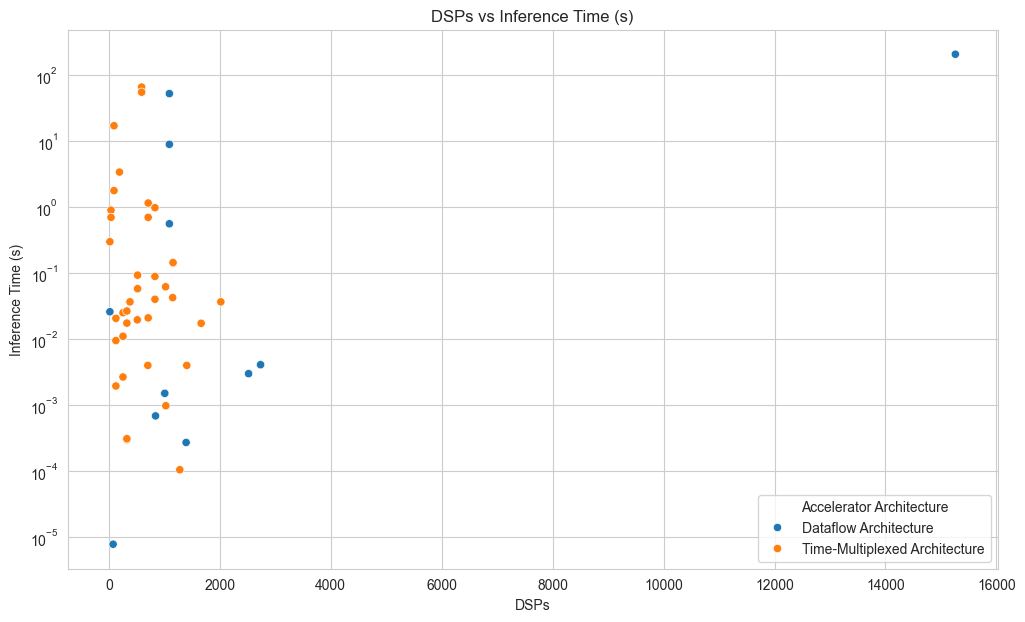

In [21]:
# Apply the function to extract DSPs and latency
temp_df = df_for_analysis[['FPGA Resources Consumption', 'Inference Time (Latency)', 'Accelerator Architecture']].dropna()
temp_df['Inference Time (s)'] = temp_df['Inference Time (Latency)'].apply(convert_time_units)
temp_df['DSPs'] = temp_df['FPGA Resources Consumption'].apply(extract_dsp)
temp_df = temp_df.dropna()
# Plot the data with a logarithmic scale on the y-axis and different colors for 'Accelerator Architecture'
scatter_plot(temp_df, 'DSPs', 'Inference Time (s)', 'DSPs vs Inference Time (s)', hue='Accelerator Architecture', x_log=False, y_log=True, legend_x=1, legend_y=0, legend_xanchor='right', legend_yanchor='lower')


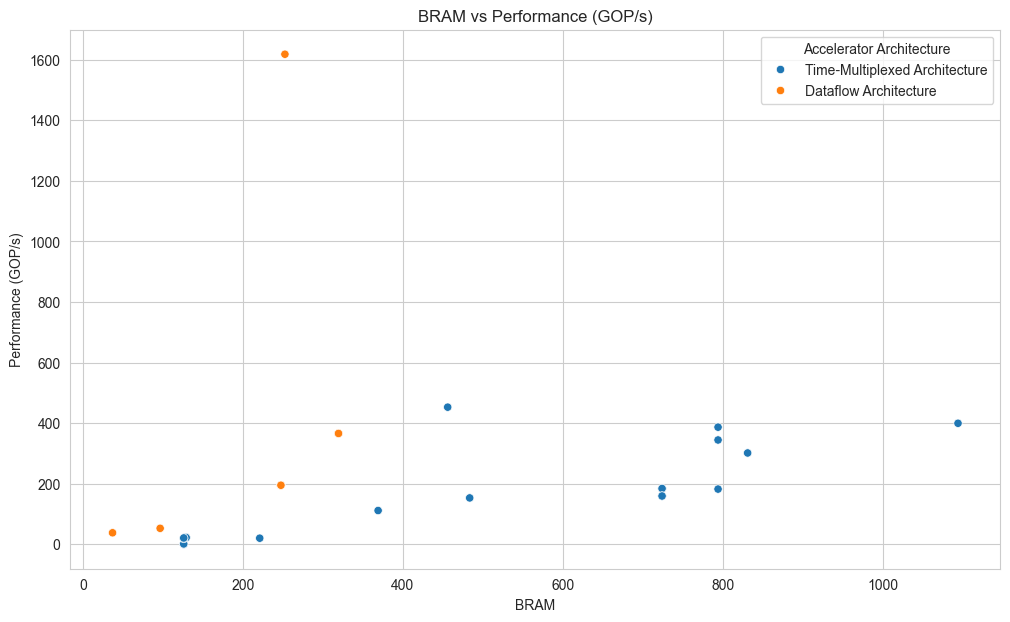

In [22]:
temp_df = df_for_analysis[['FPGA Resources Consumption', 'Performance (GOP/s)', 'Accelerator Architecture']].dropna()
temp_df['BRAM'] = temp_df['FPGA Resources Consumption'].apply(extract_bram)
temp_df['Performance (GOP/s)'] = temp_df['Performance (GOP/s)'].str.extract(r'(\d+(?:\.\d+)?)')[0].astype(float)
temp_df = temp_df.dropna()

scatter_plot(temp_df, 'BRAM', 'Performance (GOP/s)', 'BRAM vs Performance (GOP/s)', hue='Accelerator Architecture', x_log=False, y_log=False, legend_x=1, legend_y=1, legend_xanchor='right', legend_yanchor='upper')

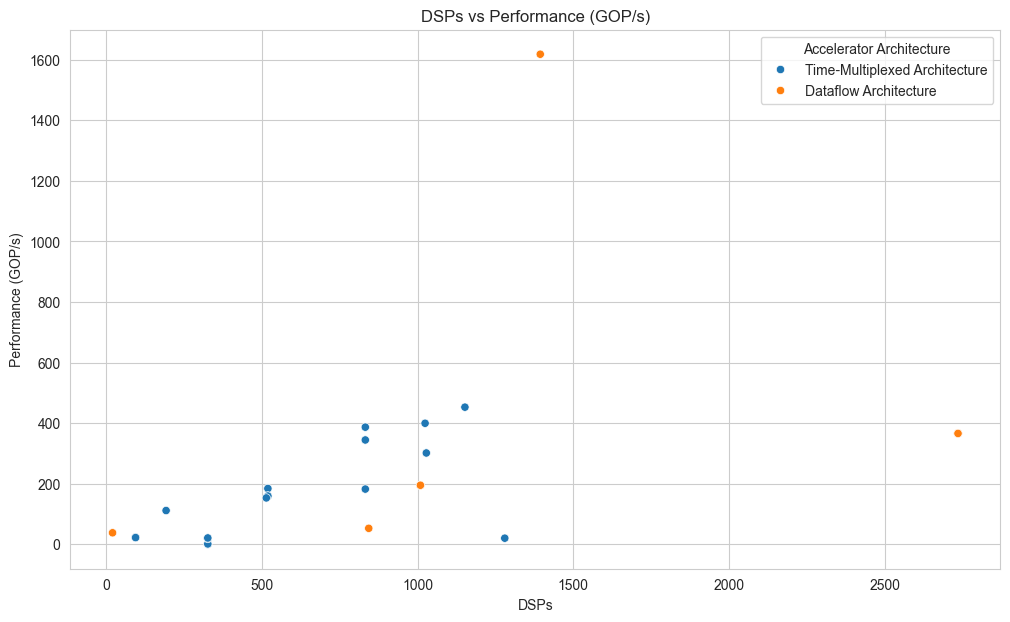

In [23]:
temp_df['DSPs'] = temp_df['FPGA Resources Consumption'].apply(extract_dsp)
temp_df = temp_df.dropna()

scatter_plot(temp_df, 'DSPs', 'Performance (GOP/s)', 'DSPs vs Performance (GOP/s)', hue='Accelerator Architecture', x_log=False, y_log=False, legend_x=1, legend_y=1, legend_xanchor='right', legend_yanchor='upper')

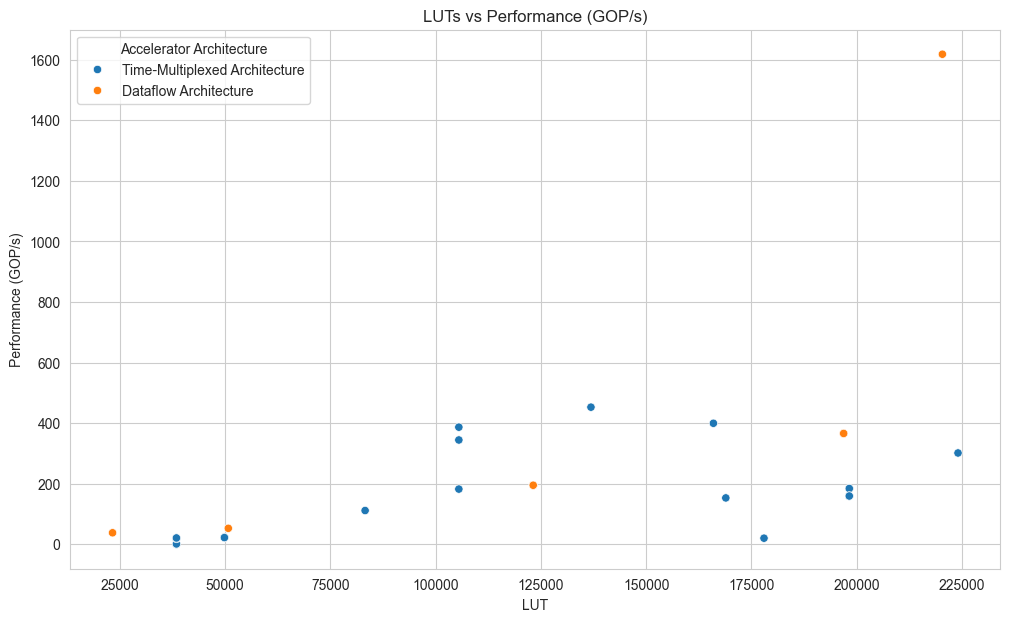

In [24]:
temp_df['LUT'] = temp_df['FPGA Resources Consumption'].apply(extract_lut)
temp_df = temp_df.dropna()

scatter_plot(temp_df, 'LUT', 'Performance (GOP/s)', 'LUTs vs Performance (GOP/s)', hue='Accelerator Architecture', x_log=False, y_log=False, legend_x=0, legend_y=1, legend_xanchor='left', legend_yanchor='upper')

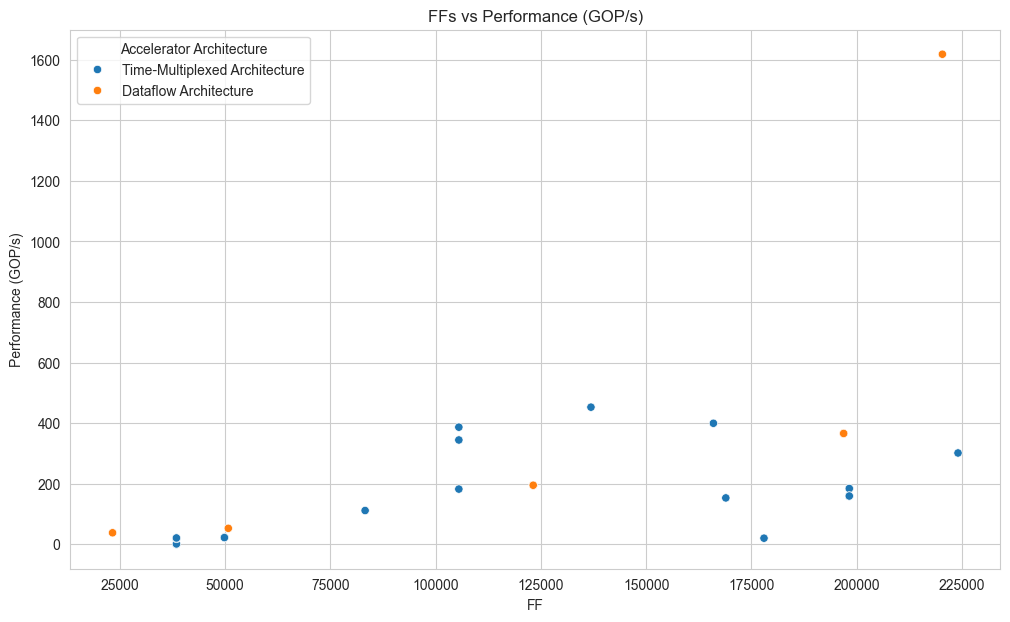

In [25]:
temp_df['FF'] = temp_df['FPGA Resources Consumption'].apply(extract_lut)
temp_df = temp_df.dropna()

scatter_plot(temp_df, 'FF', 'Performance (GOP/s)', 'FFs vs Performance (GOP/s)', hue='Accelerator Architecture', x_log=False, y_log=False, legend_x=0, legend_y=1, legend_xanchor='left', legend_yanchor='upper')

## Energy related graphs

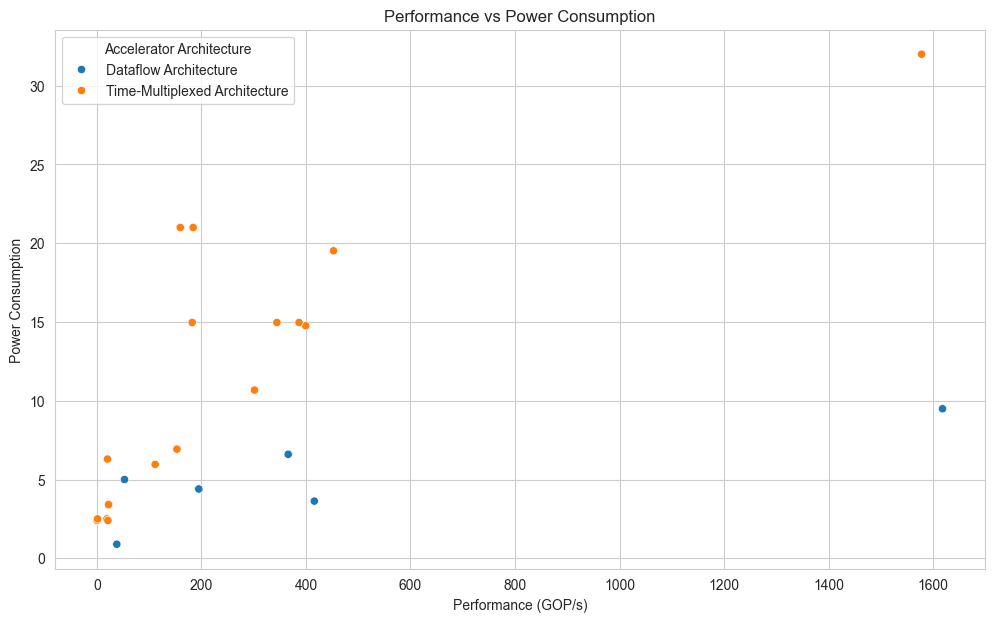

In [26]:
# Apply the function to extract BRAM and latency
temp_df = df_for_analysis[['Performance (GOP/s)', 'Power Consumption', 'Accelerator Architecture']].dropna()

# Extract numeric values from 'Performance (GOP/s)' and convert to float
temp_df['Performance (GOP/s)'] = temp_df['Performance (GOP/s)'].str.extract(r'(\d+(?:\.\d+)?)')[0].astype(float)
# Extract numeric values from 'Power Consumption' and convert to float
temp_df['Power Consumption'] = temp_df['Power Consumption'].str.extract(r'(\d+(?:\.\d+)?)')[0].astype(float)

scatter_plot(temp_df, 'Performance (GOP/s)', 'Power Consumption', 'Performance vs Power Consumption', hue='Accelerator Architecture', x_log=False, y_log=False, legend_x=0, legend_y=1, legend_xanchor='left', legend_yanchor='upper')

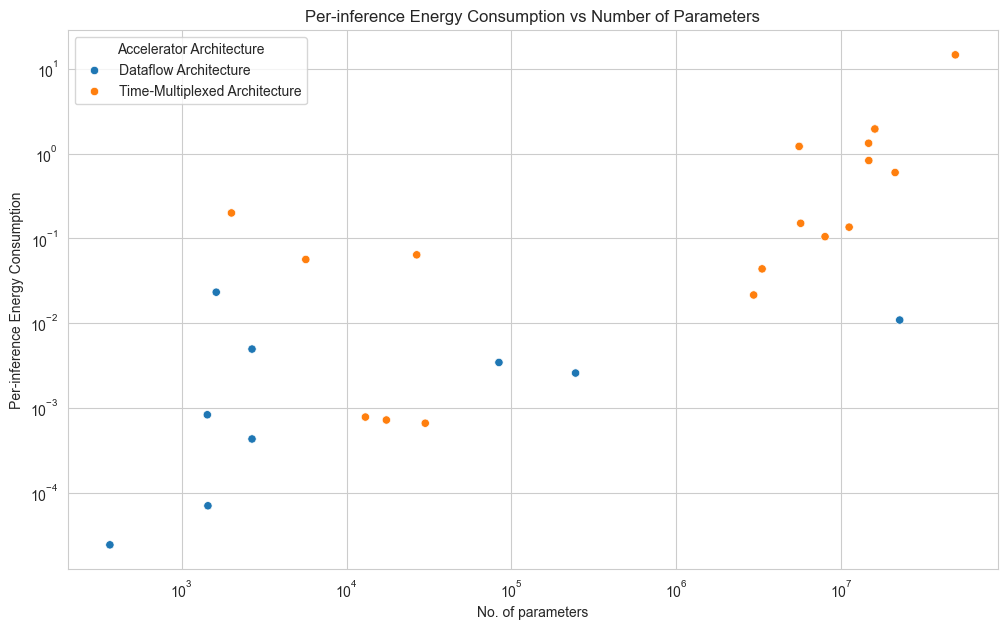

In [27]:
# Apply the function to extract BRAM and latency
temp_df = df_for_analysis[['Per-inference Energy Consumption', 'No. of parameters', 'Accelerator Architecture']].dropna()

# Extract numeric values from 'Performance (GOP/s)' and convert to float
temp_df['Per-inference Energy Consumption'] = temp_df['Per-inference Energy Consumption'].apply(convert_energy_units)
# Extract numeric values from 'Power Consumption' and convert to float
temp_df['No. of parameters'] = temp_df['No. of parameters'].str.extract(r'(\d+(?:\.\d+)?)')[0].astype(float)
temp_df = temp_df.dropna()

scatter_plot(temp_df, 'No. of parameters', 'Per-inference Energy Consumption', 'Per-inference Energy Consumption vs Number of Parameters', hue='Accelerator Architecture', x_log=True, y_log=True, legend_x=0, legend_y=1, legend_xanchor='left', legend_yanchor='upper')

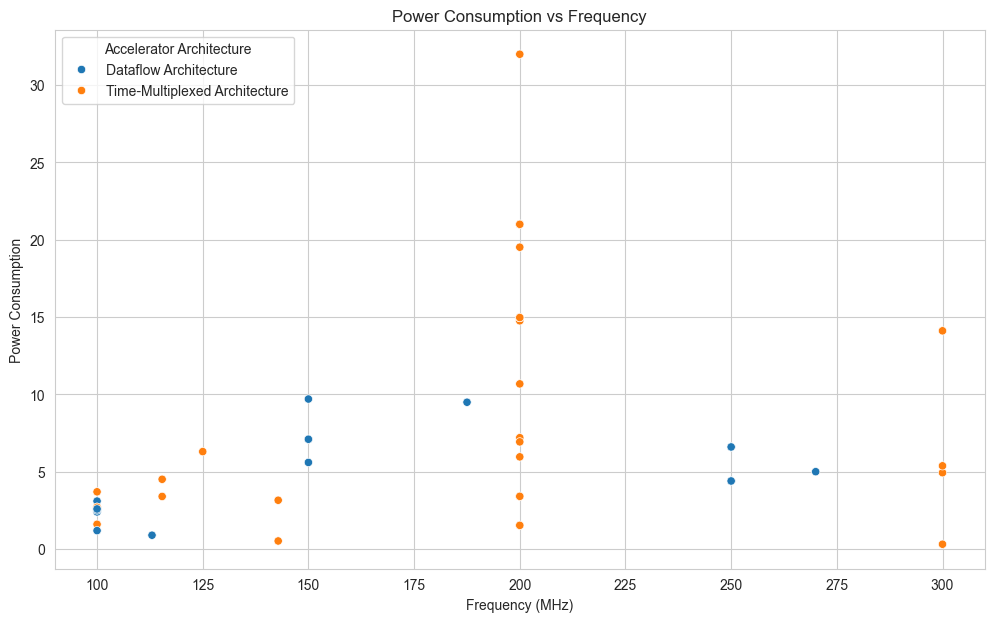

In [28]:
# Apply the function to extract BRAM and latency
temp_df = df_for_analysis[['Power Consumption', 'Frequency (MHz)', 'Accelerator Architecture']].dropna()

# Extract numeric values from 'Power Consumption' and convert to float
temp_df['Power Consumption'] = temp_df['Power Consumption'].str.extract(r'(\d+(?:\.\d+)?)')[0].astype(float)
# Extract numeric values from 'Frequency (MHz)' and convert to float
temp_df['Frequency (MHz)'] = temp_df['Frequency (MHz)'].str.extract(r'(\d+(?:\.\d+)?)')[0].astype(float)


scatter_plot(temp_df, 'Frequency (MHz)', 'Power Consumption', 'Power Consumption vs Frequency', hue='Accelerator Architecture', x_log=False, y_log=False, legend_x=0, legend_y=1, legend_xanchor='left', legend_yanchor='upper')

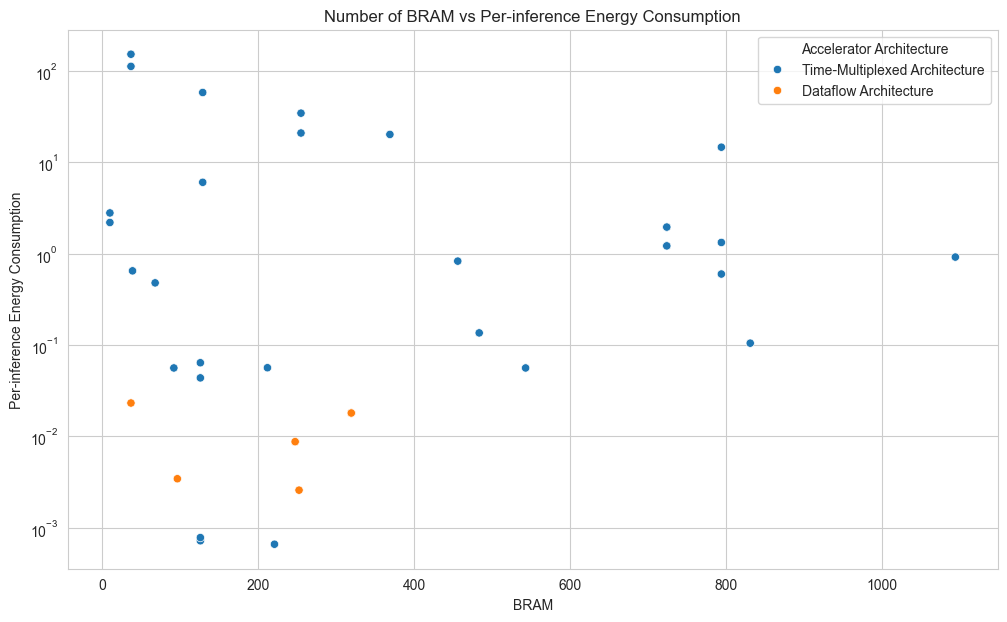

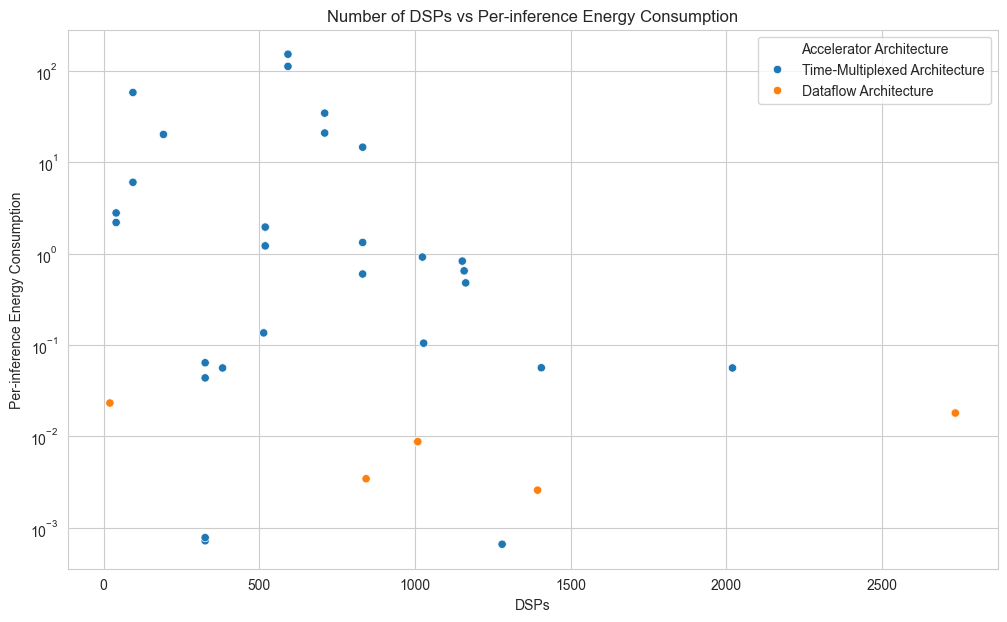

In [29]:
# Apply the function to extract DSPs and latency
temp_df = df_for_analysis[['FPGA Resources Consumption', 'Per-inference Energy Consumption', 'Accelerator Architecture']].dropna()
temp_df['Per-inference Energy Consumption'] = temp_df['Per-inference Energy Consumption'].apply(convert_energy_units)
temp_df['DSPs'] = temp_df['FPGA Resources Consumption'].apply(extract_dsp)
temp_df['BRAM'] = temp_df['FPGA Resources Consumption'].apply(extract_bram)
# Remove rows with NaN values
temp_df = temp_df.dropna()

scatter_plot(temp_df, 'BRAM', 'Per-inference Energy Consumption', 'Number of BRAM vs Per-inference Energy Consumption', hue='Accelerator Architecture', x_log=False, y_log=True, legend_x=1, legend_y=1, legend_xanchor='right', legend_yanchor='upper')

scatter_plot(temp_df, 'DSPs', 'Per-inference Energy Consumption', 'Number of DSPs vs Per-inference Energy Consumption', hue='Accelerator Architecture', x_log=False, y_log=True, legend_x=1, legend_y=1, legend_xanchor='right', legend_yanchor='upper')

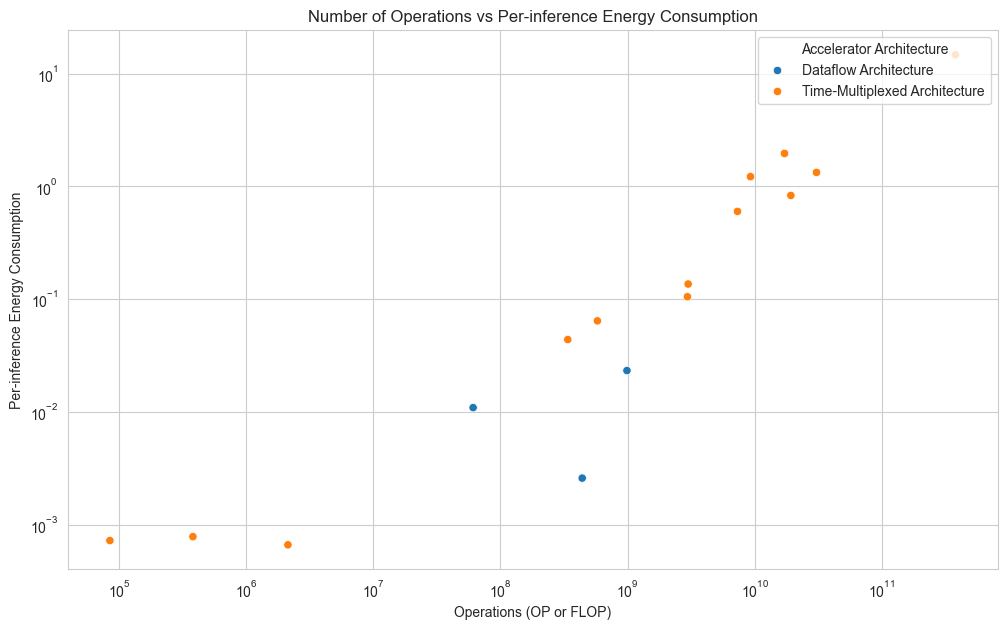

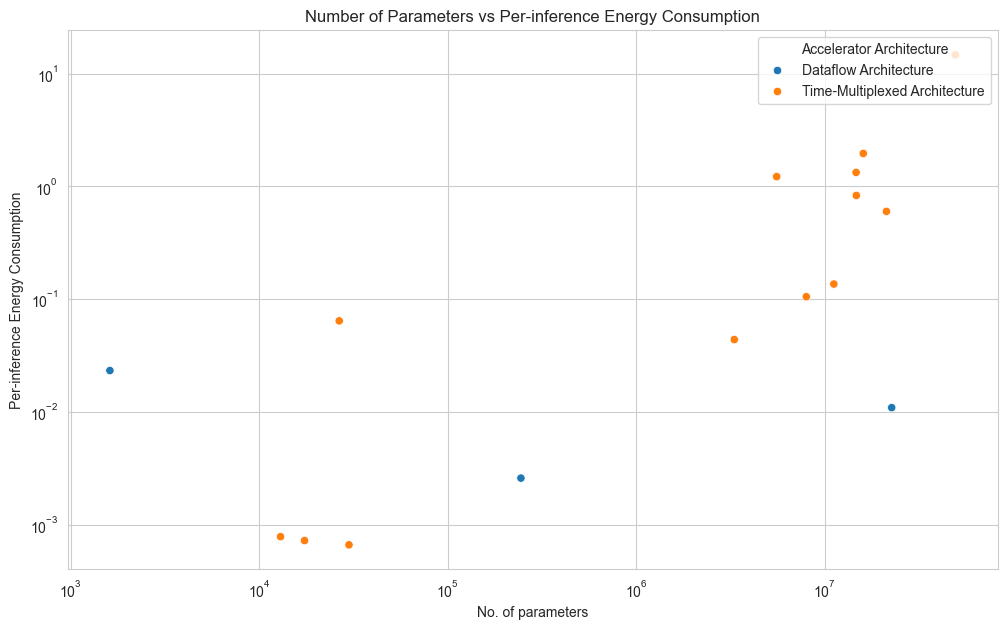

In [30]:
temp_df = df_for_analysis[['Operations (OP or FLOP)', 'Per-inference Energy Consumption', 'No. of parameters', 'Throughput', 'Accelerator Architecture']].dropna()

temp_df['Per-inference Energy Consumption'] = temp_df['Per-inference Energy Consumption'].apply(convert_energy_units)
temp_df['Operations (OP or FLOP)'] = temp_df['Operations (OP or FLOP)'].apply(convert_ops)
temp_df['No. of parameters'] = temp_df['No. of parameters'].str.extract(r'(\d+(?:\.\d+)?)')[0].astype(float)
temp_df['Throughput'] = temp_df['Throughput'].str.extract(r'(\d+(?:\.\d+)?)')[0].astype(float)
# Remove rows with NaN values
temp_df = temp_df.dropna()

scatter_plot(temp_df, 'Operations (OP or FLOP)', 'Per-inference Energy Consumption', 'Number of Operations vs Per-inference Energy Consumption', hue='Accelerator Architecture', x_log=True, y_log=True, legend_x=1, legend_y=1, legend_xanchor='right', legend_yanchor='upper')
scatter_plot(temp_df, 'No. of parameters', 'Per-inference Energy Consumption', 'Number of Parameters vs Per-inference Energy Consumption', hue='Accelerator Architecture', x_log=True, y_log=True, legend_x=1, legend_y=1, legend_xanchor='right', legend_yanchor='upper')

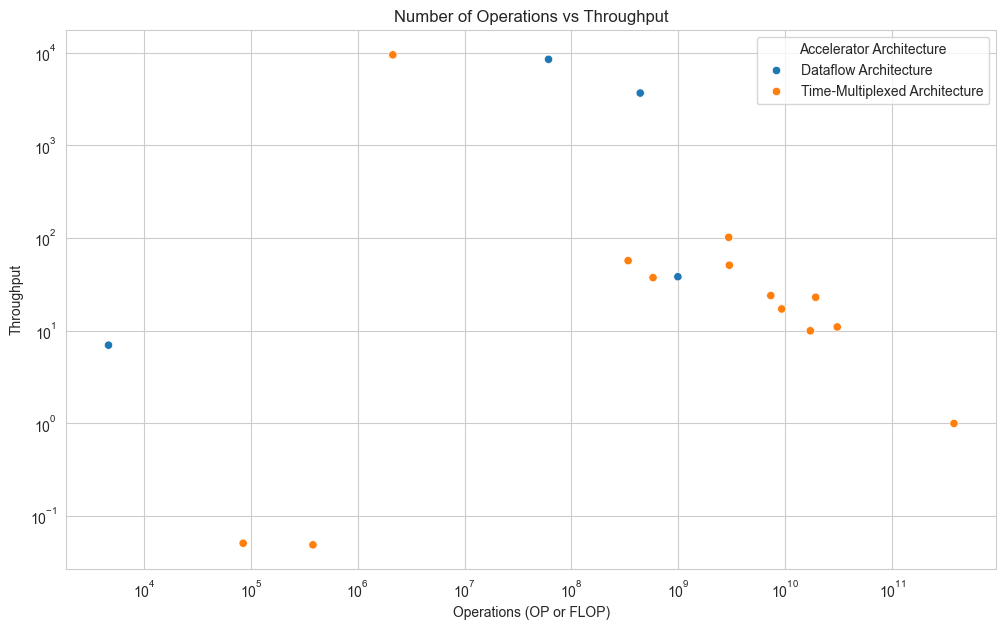

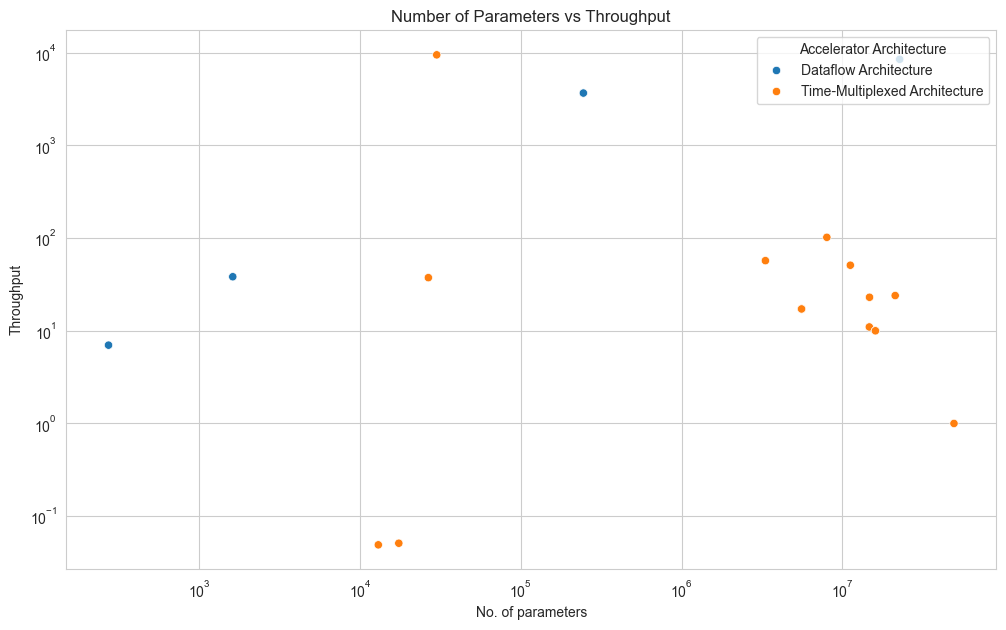

In [31]:
temp_df = df_for_analysis[['Operations (OP or FLOP)', 'Inference Time (Latency)', 'No. of parameters', 'Throughput', 'Accelerator Architecture']].dropna()

temp_df['Inference Time (Latency)'] = temp_df['Inference Time (Latency)'].apply(convert_time_units)
temp_df['Operations (OP or FLOP)'] = temp_df['Operations (OP or FLOP)'].apply(convert_ops)
temp_df['No. of parameters'] = temp_df['No. of parameters'].str.extract(r'(\d+(?:\.\d+)?)')[0].astype(float)
temp_df['Throughput'] = temp_df['Throughput'].str.extract(r'(\d+(?:\.\d+)?)')[0].astype(float)
# Remove rows with NaN values
temp_df = temp_df.dropna()

scatter_plot(temp_df, 'Operations (OP or FLOP)', 'Throughput', 'Number of Operations vs Throughput', hue='Accelerator Architecture', x_log=True, y_log=True, legend_x=1, legend_y=1, legend_xanchor='right', legend_yanchor='upper')
scatter_plot(temp_df, 'No. of parameters', 'Throughput', 'Number of Parameters vs Throughput', hue='Accelerator Architecture', x_log=True, y_log=True, legend_x=1, legend_y=1, legend_xanchor='right', legend_yanchor='upper')

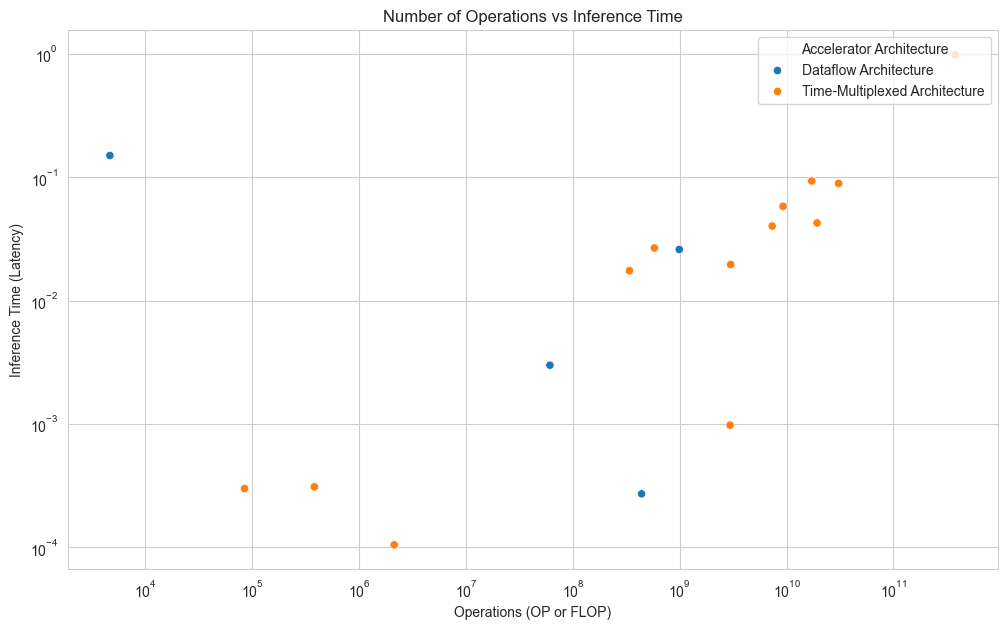

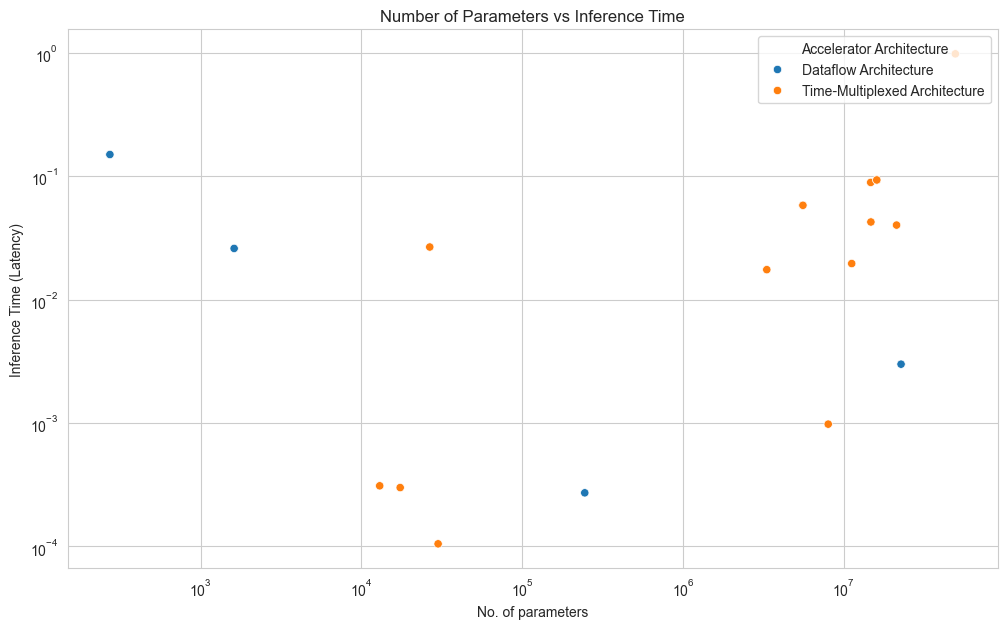

In [32]:
scatter_plot(temp_df, 'Operations (OP or FLOP)', 'Inference Time (Latency)', 'Number of Operations vs Inference Time', hue='Accelerator Architecture', x_log=True, y_log=True, legend_x=1, legend_y=1, legend_xanchor='right', legend_yanchor='upper')
scatter_plot(temp_df, 'No. of parameters', 'Inference Time (Latency)', 'Number of Parameters vs Inference Time', hue='Accelerator Architecture', x_log=True, y_log=True, legend_x=1, legend_y=1, legend_xanchor='right', legend_yanchor='upper')

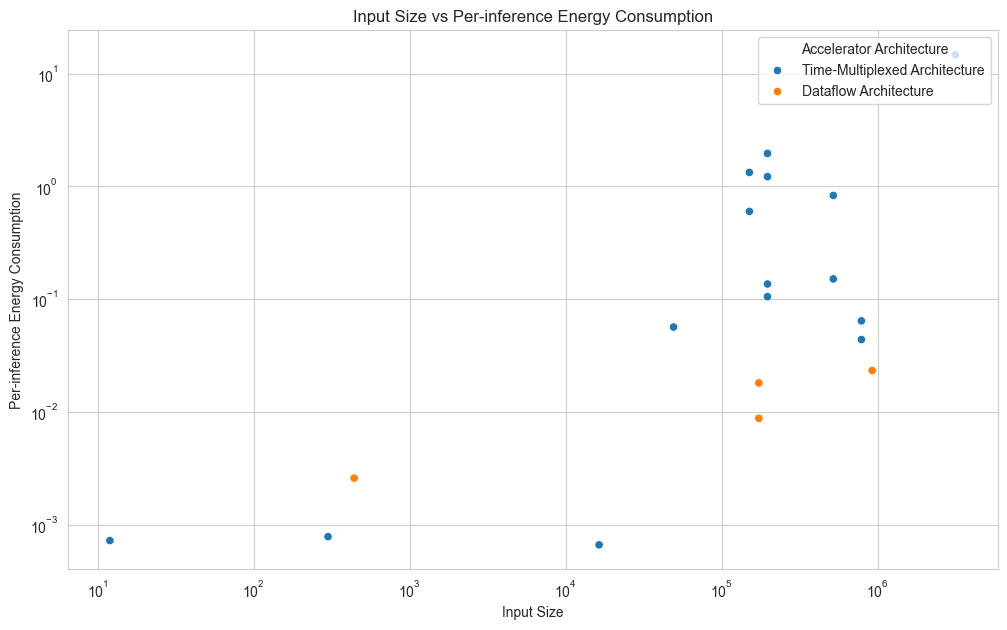

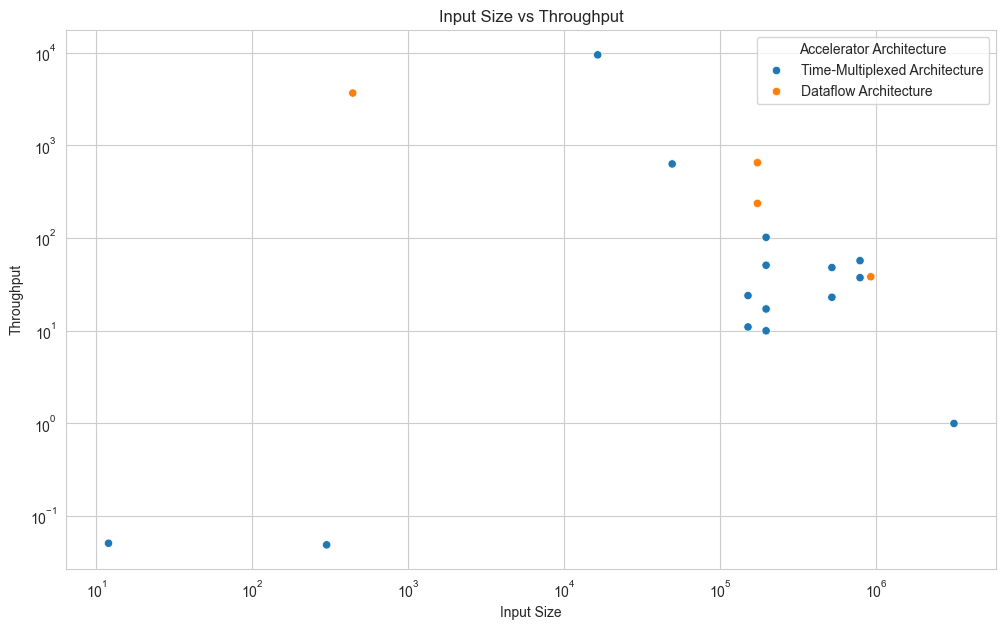

In [33]:
temp_df = df_for_analysis[['Input Size', 'Per-inference Energy Consumption', 'No. of parameters', 'Throughput', 'Accelerator Architecture']].dropna()
temp_df['Input Size'] = temp_df['Input Size'].apply(convert_input_size)
temp_df['Throughput'] = temp_df['Throughput'].str.extract(r'(\d+(?:\.\d+)?)')[0].astype(float)
temp_df['Per-inference Energy Consumption'] = temp_df['Per-inference Energy Consumption'].apply(convert_energy_units)
tmp_df = temp_df.dropna()

scatter_plot(tmp_df, 'Input Size', 'Per-inference Energy Consumption', 'Input Size vs Per-inference Energy Consumption', hue='Accelerator Architecture', x_log=True, y_log=True, legend_x=1, legend_y=1, legend_xanchor='right', legend_yanchor='upper')
scatter_plot(tmp_df, 'Input Size', 'Throughput', 'Input Size vs Throughput', hue='Accelerator Architecture', x_log=True, y_log=True, legend_x=1, legend_y=1, legend_xanchor='right', legend_yanchor='upper')